# 10 Minute School — YouTube Channel Analysis
**Tools:** YouTube Data API v3 · Pandas · Matplotlib · Seaborn  
**Goal:** Analyze content performance — which subjects, video lengths, and upload patterns drive the most views

## 1. Setup & API Connection

In [ ]:
from googleapiclient.discovery import build
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re, os
import os
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("YOUTUBE_API_KEY")
CHANNEL_ID = "UCpeKK_DqdGSQqSPhLGphRiQ"  # 10 Minute School main channel

youtube = build("youtube", "v3", developerKey=API_KEY)
sns.set_theme(style="whitegrid", palette="muted")
print("✅ Connected to YouTube API")

c:\Users\USERAS\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.82.1. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


✅ Connected to YouTube API


## 2. Channel Overview

In [2]:
r = youtube.channels().list(part="statistics,snippet", id=CHANNEL_ID).execute()
s = r["items"][0]["statistics"]

print("📺 Channel: 10 Minute School")
print(f"   Subscribers : {int(s['subscriberCount']):,}")
print(f"   Total views  : {int(s['viewCount']):,}")
print(f"   Total videos : {int(s['videoCount']):,}")

📺 Channel: 10 Minute School
   Subscribers : 1,570,000
   Total views  : 87,949,861
   Total videos : 2,837


## 3. Fetch All Video IDs

In [3]:
# Get uploads playlist
r = youtube.channels().list(part="contentDetails", id=CHANNEL_ID).execute()
playlist_id = r["items"][0]["contentDetails"]["relatedPlaylists"]["uploads"]

ids, token = [], None
while True:
    r = youtube.playlistItems().list(
        part="contentDetails", playlistId=playlist_id,
        maxResults=50, pageToken=token
    ).execute()
    ids += [i["contentDetails"]["videoId"] for i in r["items"]]
    token = r.get("nextPageToken")
    if not token:
        break

print(f"✅ Total videos found: {len(ids)}")

✅ Total videos found: 2845


## 4. Fetch Video Details (Views, Likes, Duration)

In [4]:
rows = []
for i in range(0, len(ids), 50):
    batch = ids[i:i+50]
    r = youtube.videos().list(
        part="snippet,statistics,contentDetails",
        id=",".join(batch)
    ).execute()
    for item in r["items"]:
        sn = item["snippet"]
        st = item.get("statistics", {})
        cd = item.get("contentDetails", {})
        dur = cd.get("duration", "PT0S")
        m = re.match(r"PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?", dur)
        seconds = int(m.group(1) or 0)*3600 + int(m.group(2) or 0)*60 + int(m.group(3) or 0) if m else 0
        rows.append({
            "video_id"    : item["id"],
            "title"       : sn.get("title", ""),
            "published"   : sn.get("publishedAt", "")[:10],
            "views"       : int(st.get("viewCount", 0)),
            "likes"       : int(st.get("likeCount", 0)),
            "comments"    : int(st.get("commentCount", 0)),
            "duration_sec": seconds,
        })

df = pd.DataFrame(rows)
df["duration_min"] = df["duration_sec"] / 60
df.to_csv("10ms_videos.csv", index=False)
print(f"✅ Saved 10ms_videos.csv")
df.head()

✅ Saved 10ms_videos.csv


,video_id,title,published,views,likes,comments,duration_sec,duration_min
0,bkbtcqCa3zQ,🔴 LIVE: HSC 26 Supplementary পরীক্ষার ICT-এর C...,2026-11-15,654,26,1,1500,25.000000
1,5ehxn--aE5o,টেস্ট বা যেকোনো পরীক্ষায় Economics-এ ভালো করত...,2026-11-14,1470,93,13,2253,37.550000
2,ZghX5azrns8,Formal Letter-এ ভালো মার্কস পেতে এই ভিডিওটি তো...,2026-11-13,399,17,1,211,3.516667
3,1IvCzyiAaBk,"HSC 27, টেস্ট পরীক্ষা থেকে HSC-প্রস্তুতি গুছিয...",2026-11-13,3389,134,9,88,1.466667
4,61NYGMyv1eQ,"এই পরীক্ষাও শেষ হবে, শুধু নিজের ওপর বিশ্বাস রা...",2026-11-11,1011,16,1,104,1.733333


## 5. Subject Tagging

In [5]:
SUBJECTS = {
    "HSC": ["hsc", "higher secondary"],
    "SSC": ["ssc", "secondary"],
    "Physics": ["physics", "পদার্থ"],
    "Chemistry": ["chemistry", "রসায়ন"],
    "Biology": ["biology", "জীববিজ্ঞান"],
    "Math": ["math", "গণিত", "algebra", "calculus"],
    "English": ["english", "grammar", "vocabulary"],
    "Bangla": ["bangla", "বাংলা"],
    "ICT": ["ict", "programming", "python", "computer"],
    "Admission": ["admission", "ভর্তি"],
    "Motivation": ["motivation", "motivational"],
    "BCS": ["bcs", "government job"],
}

def tag_subject(title):
    t = title.lower()
    for subj, kws in SUBJECTS.items():
        if any(k in t for k in kws):
            return subj
    return "Other"

df["subject"] = df["title"].apply(tag_subject)
df["subject"].value_counts()

subject
HSC           744
Other         617
Admission     435
Physics       188
Math          186
Bangla        185
English       168
Biology       150
Chemistry     123
ICT            32
SSC            11
BCS             4
Motivation      2
Name: count, dtype: int64

## 6. Chart 1 — Top 10 Most Viewed Videos

C:\Users\USERAS\AppData\Local\Temp\ipykernel_28988\89127720.py:9: UserWarning: Glyph 2477 (\N{BENGALI LETTER BHA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\USERAS\AppData\Local\Temp\ipykernel_28988\89127720.py:9: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
C:\Users\USERAS\AppData\Local\Temp\ipykernel_28988\89127720.py:9: UserWarning: Glyph 2503 (\N{BENGALI VOWEL SIGN E}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\USERAS\AppData\Local\Temp\ipykernel_28988\89127720.py:9: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\USERAS\AppData\Local\Temp\ipykernel_28988\89127720.py:9: UserWarning: Glyph 2509 (\N{BENGALI SIGN VIRAMA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\USERAS\AppData\Local\Temp\ipykernel_28988\89127720.py:9: UserWarning: Glyph 2463 (\N{BENGALI LETTER TTA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\USERAS\AppDat

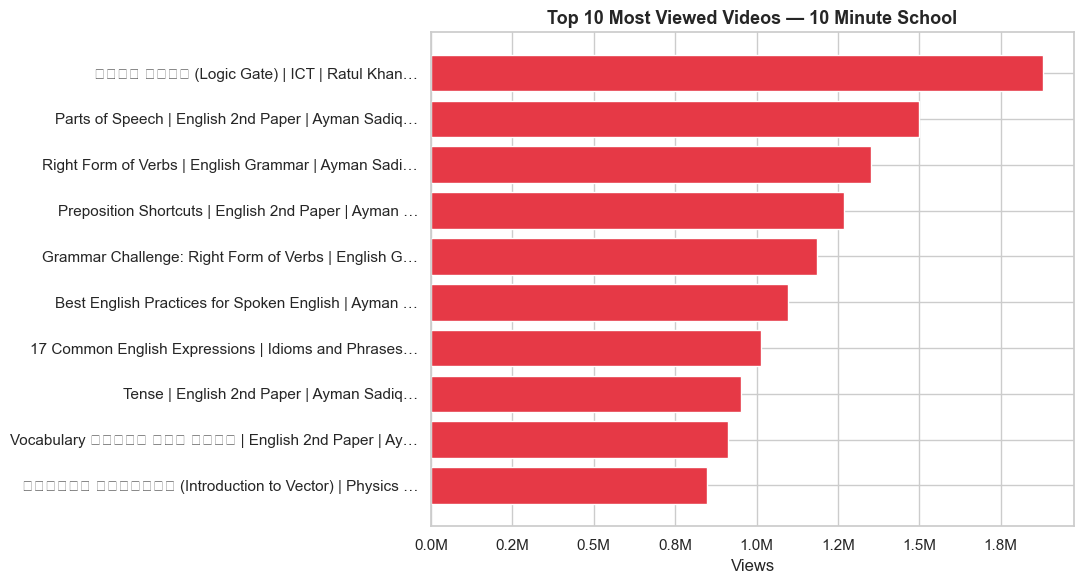

In [ ]:
top10 = df.nlargest(10, "views")[["title", "views"]].copy()
top10["title"] = top10["title"].str[:50] + "…"

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10["title"][::-1], top10["views"][::-1], color="#E63946")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.set_xlabel("Views")
ax.set_title("Top 10 Most Viewed Videos — 10 Minute School", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Chart 2 — Average Views by Subject

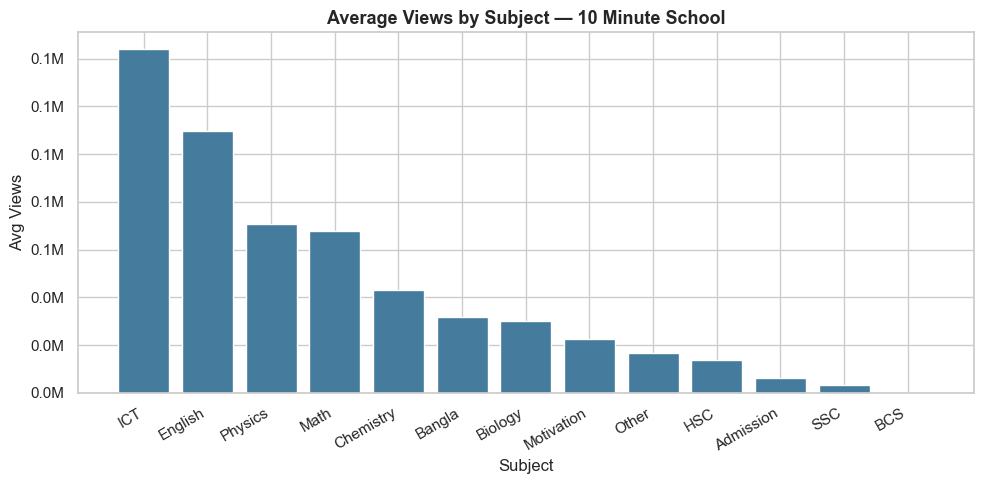

In [ ]:
subj_avg = df.groupby("subject")["views"].mean().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(subj_avg["subject"], subj_avg["views"], color="#457B9D")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.set_title("Average Views by Subject — 10 Minute School", fontweight="bold", fontsize=13)
ax.set_xlabel("Subject")
ax.set_ylabel("Avg Views")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 8. Chart 3 — Video Length vs Views

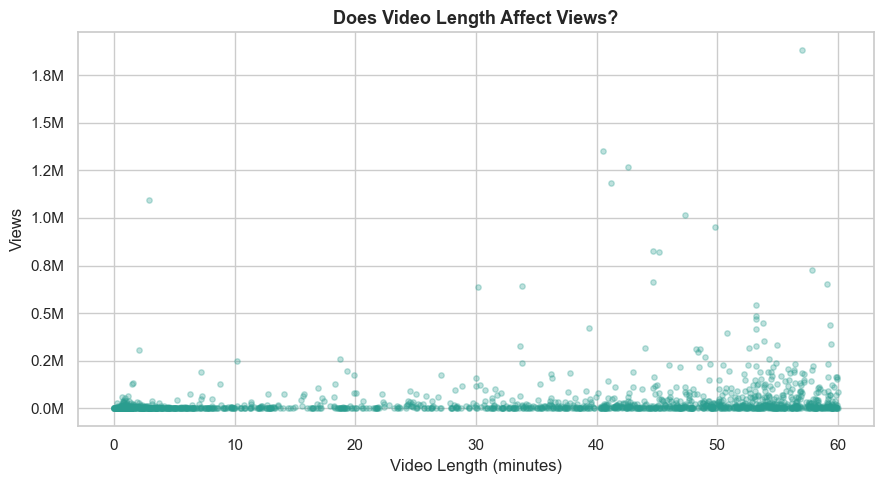

In [ ]:
sample = df[df["duration_min"] < 60].copy()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample["duration_min"], sample["views"], alpha=0.3, s=15, color="#2A9D8F")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.set_xlabel("Video Length (minutes)")
ax.set_ylabel("Views")
ax.set_title("Does Video Length Affect Views?", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 9. Chart 4 — Monthly Upload Frequency

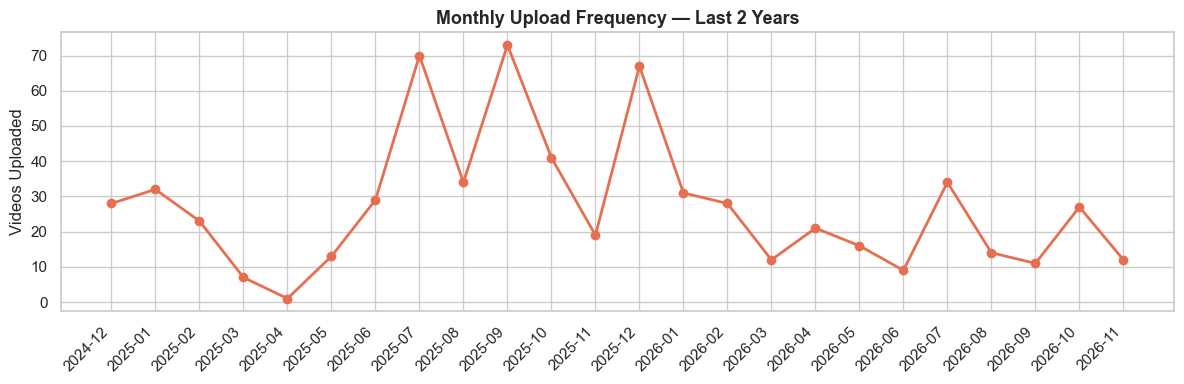

In [ ]:
df["year_month"] = df["published"].str[:7]
monthly = df.groupby("year_month").size().reset_index(name="uploads").tail(24)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly["year_month"], monthly["uploads"], marker="o", color="#E76F51", linewidth=2)
ax.set_title("Monthly Upload Frequency — Last 2 Years", fontweight="bold", fontsize=13)
ax.set_ylabel("Videos Uploaded")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 10. Key Findings

In [10]:
top = df.nlargest(1, "views").iloc[0]
best_subj = df.groupby("subject")["views"].mean().idxmax()
sweet = df[(df["duration_min"] >= 8) & (df["duration_min"] <= 15)]["views"].mean()
overall = df["views"].mean()
pct = (sweet - overall) / overall * 100

print("=" * 55)
print("📊 KEY FINDINGS")
print("=" * 55)
print(f"🏆 Most viewed : {top['title'][:55]}")
print(f"   Views       : {top['views']:,}")
print(f"\n📚 Highest avg views subject : {best_subj}")
print(f"\n⏱  8–15 min videos avg views : {sweet:,.0f}")
print(f"   Overall avg views          : {overall:,.0f}")
print(f"   → 8–15 min videos get {pct:+.0f}% vs average")
print(f"\n💬 Avg like rate : {(df['likes']/df['views'].replace(0,1)).mean()*100:.2f}%")
print("=" * 55)

📊 KEY FINDINGS
🏆 Most viewed : লজিক গেইট (Logic Gate) | ICT | Ratul Khan
   Views       : 1,881,294

📚 Highest avg views subject : ICT

⏱  8–15 min videos avg views : 10,725
   Overall avg views          : 30,822
   → 8–15 min videos get -65% vs average

💬 Avg like rate : 2.99%
